<div style="text-align: center;"><h1 style="margin-bottom: 10px; font-weight: bold;">EXPLORATORY DATA ANALYSIS</h1></div>

## **Objective**

The objective of this analysis is to understand employee attrition patterns
and examine employee, job, compensation, and workplace characteristics
associated with attrition.

The analysis focuses on:
- Overall attrition levels
- Differences across departments and job roles
- Compensation and job level
- Employee tenure
- Job satisfaction
- Other potentially relevant employee and workplace characteristics

The findings from this EDA will be used to guide predictive modeling
and the Power BI dashboard.

## **Import Master Dataset**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/hr_employee_master.csv")
print("Shape:", df.shape)

Shape: (4410, 26)


## **Attrition Overview**

### Overall Attrition

*What is the overall attrition level in the employee population?*

#### Analysis

In [3]:
total = len(df)
left = (df["Attrition"] == "Yes").sum()
stayed = (df["Attrition"] == "No").sum()
rate = left / total * 100

print(f"Total Employees : {total:,}")
print(f"Employees Left  : {left:,}")
print(f"Employees Stayed: {stayed:,}")
print(f"Attrition Rate  : {rate:.2f}%")

Total Employees : 4,410
Employees Left  : 711
Employees Stayed: 3,699
Attrition Rate  : 16.12%


#### Interpretation
The dataset contains 4,410 employees, of whom 711 are marked as having left the organization, resulting in an attrition rate of 16.1%.

## **Organizational Analysis**
### Attrition by Department
Does attrition vary across departments?
#### Analysis

In [4]:
department = df.groupby("Department", as_index=False).agg(
    Employees=("EmployeeID", "count"),
    Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
)

department["Attrition_Rate"] = (
    department["Attrition_Count"] / department["Employees"] * 100
).round(2)

department = department.sort_values("Attrition_Rate", ascending=False)

from IPython.display import display, HTML

display(HTML(department.to_html(index=False)))

Department,Employees,Attrition_Count,Attrition_Rate
Human Resources,189,57,30.16
Research & Development,2883,453,15.71
Sales,1338,201,15.02


#### *Interpretation*
Human Resources has the highest attrition rate at 30.16%, while Research & Development and Sales have lower attrition rates of 15.71% and 15.02%, respectively.
### Attrition by Job Role
*Which job roles have relatively higher attrition rates?*
#### Analysis

In [5]:
job_role = df.groupby("JobRole", as_index=False).agg(
    Employees=("EmployeeID", "count"),
    Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
)

job_role["Attrition_Rate"] = (
    job_role["Attrition_Count"] / job_role["Employees"] * 100
).round(2)

job_role = job_role.sort_values("Attrition_Rate", ascending=False)

display(HTML(job_role.to_html(index=False,formatters={"Attrition_Rate": "{:.2f}%".format})))

JobRole,Employees,Attrition_Count,Attrition_Rate
Research Director,240,57,23.75%
Research Scientist,876,159,18.15%
Sales Executive,978,165,16.87%
Laboratory Technician,777,126,16.22%
Healthcare Representative,393,57,14.50%
Sales Representative,249,36,14.46%
Manager,306,42,13.73%
Human Resources,156,21,13.46%
Manufacturing Director,435,48,11.03%


#### Interpretation
Attrition rates vary across job roles. Research Director has the highest attrition rate at 23.75%, while Manufacturing Director has the lowest at 11.03%.

### Attrition by Job Level
*Does attrition vary across different job levels?*
#### Analysis

In [6]:
job_level = df.groupby("JobLevel", as_index=False).agg(
    Employees=("EmployeeID", "count"),
    Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
)

job_level["Attrition_Rate"] = (
    job_level["Attrition_Count"] / job_level["Employees"] * 100
).round(2)

job_level = job_level.sort_values("JobLevel")

display(HTML(job_level.to_html(index=False,formatters={"Attrition_Rate": "{:.2f}%".format})))

JobLevel,Employees,Attrition_Count,Attrition_Rate
1,1629,252,15.47%
2,1602,285,17.79%
3,654,96,14.68%
4,318,51,16.04%
5,207,27,13.04%


#### Interpretation

Attrition is highest at Job Level 2 (17.79%) and lowest at Job Level 5 (13.04%) with no consistent trend across job levels.

## **Compensation & Tenure Analysis**
### Attrition by Monthly Income
*How is attrition associated with monthly income?*
#### Analysis

In [7]:
income = df.groupby("Attrition")["MonthlyIncome"].agg(
    Count="count",
    Mean="mean",
    Median="median"
).reset_index().round(2)

income

display(HTML(income.to_html(index=False)))

Attrition,Count,Mean,Median
No,3699,65672.60,49300.0
Yes,711,61682.62,49080.0


#### Visualization

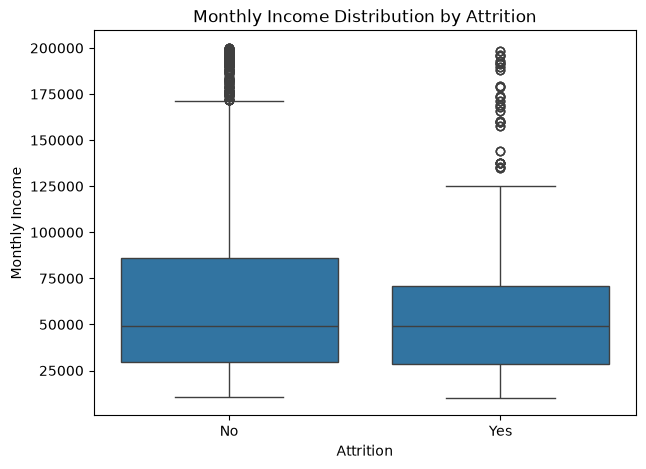

In [8]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")

plt.title("Monthly Income Distribution by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")
plt.show()

#### Interpretation

Employees who left had a slightly lower median monthly income (₹49,080)
than those who stayed (₹49,300), with both groups showing high-income outliers.

### Attrition by Tenure

*Does attrition vary across different levels of employee tenure?*

#### Analysis

In [10]:
tenure_bins = [0, 2, 5, 10, 15, float("inf")]
tenure_labels = [
    "0–2 years", "3–5 years", "6–10 years",
    "11–15 years", "16+ years"
]

df["Tenure_Group"] = pd.cut(
    df["YearsAtCompany"],
    bins=tenure_bins,
    labels=tenure_labels
)

tenure = (
    df
    .groupby("Tenure_Group", observed=True, as_index=False)
    .agg(
        Employees=("EmployeeID", "count"),
        Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
    )
)

tenure["Attrition_Rate"] = (
    tenure["Attrition_Count"] / tenure["Employees"] * 100
)

display(HTML(tenure.to_html(index=False,formatters={"Attrition_Rate": "{:.2f}%".format})))


Tenure_Group,Employees,Attrition_Count,Attrition_Rate
0–2 years,894,258,28.86%
3–5 years,1302,180,13.82%
6–10 years,1344,165,12.28%
11–15 years,324,21,6.48%
16+ years,414,39,9.42%


#### Visualization

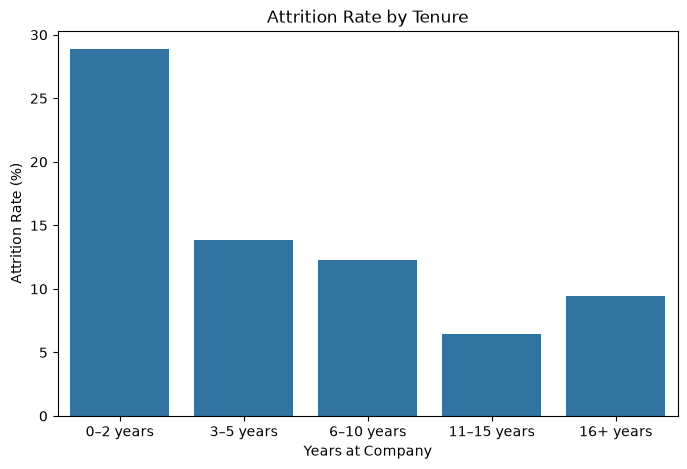

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=tenure,
    x="Tenure_Group",
    y="Attrition_Rate"
)

plt.title("Attrition Rate by Tenure")
plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")
plt.show()

#### Interpretation

Attrition is highest for employees with 0–2 years of tenure (28.86%) and
generally declines with longer tenure, with a slight increase in the 16+
years group (9.42%).

## **Employee Experience Analysis**

### Attrition by Job Satisfaction

*Is job satisfaction associated with attrition?*

#### Analysis

In [12]:
satisfaction = (
    df
    .groupby("JobSatisfaction", as_index=False)
    .agg(
        Employees=("EmployeeID", "count"),
        Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
    )
)

satisfaction["Attrition_Rate"] = (
    satisfaction["Attrition_Count"] / satisfaction["Employees"] * 100
)

display(HTML(satisfaction.to_html(index=False,formatters={"Attrition_Rate": "{:.2f}%".format})))

JobSatisfaction,Employees,Attrition_Count,Attrition_Rate
1.0,860,197,22.91%
2.0,840,138,16.43%
3.0,1343,220,16.38%
4.0,1367,156,11.41%


#### Interpretation

Attrition is highest among employees with the lowest job satisfaction (22.91%) and lowest among those with the highest satisfaction (11.41%).

## **Secondary Analysis**

### Attrition by Work-Life Balance

*Is work-life balance associated with attrition?*

#### Analysis

In [13]:
worklife = (
    df
    .groupby("WorkLifeBalance", as_index=False)
    .agg(
        Employees=("EmployeeID", "count"),
        Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
    )
)

worklife["Attrition_Rate"] = (
    worklife["Attrition_Count"] / worklife["Employees"] * 100
)

display(HTML(worklife.to_html(index=False,formatters={"Attrition_Rate": "{:.2f}%".format})))

WorkLifeBalance,Employees,Attrition_Count,Attrition_Rate
1.0,239,75,31.38%
2.0,1019,171,16.78%
3.0,2698,384,14.23%
4.0,454,81,17.84%


#### Interpretation

Attrition is highest among employees with the lowest work-life balance (31.38%),while the other levels range from 14.23% to 17.84%.

### Attrition by Business Travel

*Does attrition vary across business travel categories?*

#### Analysis

In [14]:
travel = (
    df
    .groupby("BusinessTravel", as_index=False)
    .agg(
        Employees=("EmployeeID", "count"),
        Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
    )
)

travel["Attrition_Rate"] = (
    travel["Attrition_Count"] / travel["Employees"] * 100
)

display(HTML(travel.to_html(index=False,formatters={"Attrition_Rate": "{:.2f}%".format})))

BusinessTravel,Employees,Attrition_Count,Attrition_Rate
Non-Travel,450,36,8.00%
Travel_Frequently,831,207,24.91%
Travel_Rarely,3129,468,14.96%


#### Interpretation

Attrition is highest among employees who travel frequently (24.91%) and lowest among non-travel employees (8.00%).

### Years Since Last Promotion

*Is attrition associated with the time employees have spent since their last promotion?*

#### Analysis

In [15]:
promotion_bins = [0, 2, 5, 10, float("inf")]
promotion_labels = ["0–2 years", "3–5 years", "6–10 years", "11+ years"]

df["Promotion_Group"] = pd.cut(
    df["YearsSinceLastPromotion"],
    bins=promotion_bins,
    labels=promotion_labels,
    include_lowest=True
)

promotion = (
    df
    .groupby("Promotion_Group", observed=True, as_index=False)
    .agg(
        Employees=("EmployeeID", "count"),
        Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
    )
)

promotion["Attrition_Rate"] = (
    promotion["Attrition_Count"] / promotion["Employees"] * 100
)

display(HTML(promotion.to_html(index=False, formatters={"Attrition_Rate": "{:.2f}%".format})))

Promotion_Group,Employees,Attrition_Count,Attrition_Rate
0–2 years,3291,558,16.96%
3–5 years,474,48,10.13%
6–10 years,447,81,18.12%
11+ years,198,24,12.12%


#### Interpretation

Attrition is highest among employees with 6–10 years since their last promotion(18.12%) and lowest for those with 3–5 years (10.13%).

### Years With Current Manager

*Is attrition associated with the length of time employees have worked with their current manager?*

#### Analysis

In [16]:
manager_bins = [0, 2, 5, 10, float("inf")]
manager_labels = ["0–2 years", "3–5 years", "6–10 years", "11+ years"]

df["Manager_Tenure_Group"] = pd.cut(
    df["YearsWithCurrManager"],
    bins=manager_bins,
    labels=manager_labels,
    include_lowest=True
)

manager = (
    df
    .groupby("Manager_Tenure_Group", observed=True, as_index=False)
    .agg(
        Employees=("EmployeeID", "count"),
        Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
    )
)

manager["Attrition_Rate"] = (
    manager["Attrition_Count"] / manager["Employees"] * 100
)

display(HTML(manager.to_html(index=False,formatters={"Attrition_Rate": "{:.2f}%".format})))

Manager_Tenure_Group,Employees,Attrition_Count,Attrition_Rate
0–2 years,2049,438,21.38%
3–5 years,813,102,12.55%
6–10 years,1329,162,12.19%
11+ years,219,9,4.11%


#### Interpretation

Attrition is highest among employees who have worked with their current manager for 0–2 years (21.38%) and lowest among those with 11+ years (4.11%).

## **EDA Summary**

The exploratory analysis identified several differences in attrition across
employee, job, compensation, and workplace characteristics.

- Overall attrition rate was 16.12%.
- Attrition varied across departments and job roles, with noticeable
  differences in attrition rates between groups.
- Job satisfaction showed a clear pattern, with higher attrition among
  employees reporting lower satisfaction.
- Attrition was highest among employees with 0–2 years of tenure.
- Work-life balance and business travel also showed differences in
  attrition rates across their respective categories.
- Monthly income showed only a small difference in median income between
  employees who stayed and those who left.
- Attrition rates did not follow a consistent pattern across job levels
  or years since last promotion.
- Employees with shorter tenure with their current manager showed higher
  attrition rates than those with longer manager tenure.

These observations will be used to guide the next stage of predictive
modeling and explainability analysis.